In [1]:
!pip install gdown
import gdown
url = "https://drive.google.com/drive/folders/10lBu24lkCqp8Z5J4-sj6KUYsS-1P9u59?usp=share_link"
gdown.download_folder(url, quiet = False)

Retrieving folder contents


Processing file 1fK0RWOvXOO_VOvpTyvPLtv3Y-wTqwG4t B1.npy
Processing file 1R5NOhQWJBCulEcmIHNhfg1rJS_8jP2vH B2.npy
Processing file 18VYgeQ8iCXEfGbE-SHCEyX0OO7XDWlxW coords.npy
Processing file 1avjvGGgCXdcVU4knsdF8PpMPEt9lkaiv flows_in.npy
Processing file 1Awq2sNqKJiDikalSiL6g0qSbaLd8hLd0 G_undir.pkl
Processing file 1dAMd_jq8KWsTGLkXDz1vDSb0LjG7ILgN last_nodes.npy
Processing file 16kcEwiUmd9RI1eSC84pFrPCgABwOslEN rev_flows_in.npy
Processing file 1yNYcsZV1UYPCF3Yjl2UJIuKUBPcAzt8q rev_last_nodes.npy
Processing file 1gRHO5mS-AguOAvrl2tWG4H5I1ZPwc_tc rev_target_nodes.npy
Processing file 1xYC4WnUbcNUaxae4cfVzwcAwrfH-ucEf rev_targets.npy
Processing file 1RhPaKXYuXWhHOye7Pap37U3j0T_jqv3G target_nodes.npy
Processing file 1Bo3fjfNAYRhWUY53n_gfZcuZjzyb_0TW targets.npy
Processing file 1Muxj2i32WJsibTWVc1Gkl86cSuuxM-y_ test_mask.npy
Processing file 1oEWPnrHPZnTde1b_E1KVN2Yn4LWfomFs train_mask.npy


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1fK0RWOvXOO_VOvpTyvPLtv3Y-wTqwG4t
To: /content/trajectory_data_2hop_synthetic/B1.npy
100%|██████████| 3.20M/3.20M [00:00<00:00, 103MB/s]
Downloading...
From: https://drive.google.com/uc?id=1R5NOhQWJBCulEcmIHNhfg1rJS_8jP2vH
To: /content/trajectory_data_2hop_synthetic/B2.npy
100%|██████████| 5.20M/5.20M [00:00<00:00, 67.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=18VYgeQ8iCXEfGbE-SHCEyX0OO7XDWlxW
To: /content/trajectory_data_2hop_synthetic/coords.npy
100%|██████████| 6.53k/6.53k [00:00<00:00, 15.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1avjvGGgCXdcVU4knsdF8PpMPEt9lkaiv
To: /content/trajectory_data_2hop_synthetic/flows_in.npy
100%|██████████| 8.01M/8.01M [00:00<00:00, 78.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Awq2sNqKJiDikalSiL6g0qSbaLd8hLd0
To: /content/trajectory_data_2hop_synthe

['/content/trajectory_data_2hop_synthetic/B1.npy',
 '/content/trajectory_data_2hop_synthetic/B2.npy',
 '/content/trajectory_data_2hop_synthetic/coords.npy',
 '/content/trajectory_data_2hop_synthetic/flows_in.npy',
 '/content/trajectory_data_2hop_synthetic/G_undir.pkl',
 '/content/trajectory_data_2hop_synthetic/last_nodes.npy',
 '/content/trajectory_data_2hop_synthetic/rev_flows_in.npy',
 '/content/trajectory_data_2hop_synthetic/rev_last_nodes.npy',
 '/content/trajectory_data_2hop_synthetic/rev_target_nodes.npy',
 '/content/trajectory_data_2hop_synthetic/rev_targets.npy',
 '/content/trajectory_data_2hop_synthetic/target_nodes.npy',
 '/content/trajectory_data_2hop_synthetic/targets.npy',
 '/content/trajectory_data_2hop_synthetic/test_mask.npy',
 '/content/trajectory_data_2hop_synthetic/train_mask.npy']

In [2]:
import os, sys, math, random, glob
from pathlib import Path
from types import SimpleNamespace
from collections import defaultdict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import networkx as nx
from tqdm import tqdm
import matplotlib.pyplot as plt
import pickle
import numpy as np
import networkx as nx
from pathlib import Path


def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_float32_matmul_precision("high")  # ok on recent PyTorch; no-op otherwise
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def suggest_dataset_roots(search_dirs=(".", "/content", "/content/drive/MyDrive", "/workspace")):
    """
    Search for SCoNe format folders produced by synthetic_data_gen.generate_dataset:
      trajectory_data_1hop_<suffix>/ and/or trajectory_data_2hop_<suffix>/
    """
    hits = {"1hop": [], "2hop": []}
    for d in map(Path, search_dirs):
        if not d.exists():
            continue
        for p in d.iterdir():
            if not p.is_dir():
                continue
            name = p.name
            if name.startswith("trajectory_data_1hop_"):
                hits["1hop"].append(str(p.resolve()))
            if name.startswith("trajectory_data_2hop_"):
                hits["2hop"].append(str(p.resolve()))
    return hits

def pretty_print_hits(hits):
    print(">> Discovered dataset folders:")
    if not hits["1hop"] and not hits["2hop"]:
        print("   (none found yet — you can generate with SCoNe's synthetic_data_gen.py)")
    if hits["1hop"]:
        print("   1-hop:")
        for h in hits["1hop"]:
            print("     -", h)
    if hits["2hop"]:
        print("   2-hop:")
        for h in hits["2hop"]:
            print("     -", h)

_candidates = suggest_dataset_roots()
pretty_print_hits(_candidates)

CFG = SimpleNamespace(
    seed=42,
    use_2hop=True,                 # start with 1-hop classification
    data_root="/content/trajectory_data_2hop_synthetic",                 # <-- set in next cell after we load/discover
    batch_size=256,
    epochs=20,
    lr=1e-3,
    weight_decay=1e-5,
    emb_dim=64,                     # SNN hidden size (node stalk dim)
    layers=3,                       # number of sheaf layers
    dropout=0.0,
    max_degree=None,                # will be inferred from data
)

set_seed(CFG.seed)

print(f"Device: {device}")
print(f"Python: {sys.version.split()[0]} | Torch: {torch.__version__} | NumPy: {np.__version__}")


>> Discovered dataset folders:
   2-hop:
     - /content/trajectory_data_2hop_synthetic
     - /content/trajectory_data_2hop_synthetic
Device: cpu
Python: 3.12.12 | Torch: 2.8.0+cu126 | NumPy: 2.0.2


In [3]:
def pick_data_root(candidates, use_2hop=False):
    bucket = "2hop" if use_2hop else "1hop"
    opts = candidates[bucket]
    if CFG.data_root is not None:
        return Path(CFG.data_root)
    if len(opts) == 1:
        print(f">> Using detected dataset: {opts[0]}")
        return Path(opts[0])
    elif len(opts) > 1:
        print("!! Multiple candidate datasets found. Set CFG.data_root to one of:")
        for o in opts:
            print("   ", o)
        raise ValueError("Please set CFG.data_root = '.../trajectory_data_1hop_<suffix>' (or 2hop).")
    else:
        raise FileNotFoundError("No SCoNe dataset folder found. Generate with synthetic_data_gen.py and rerun.")

def _read_gpickle_compat(path: Path):
    # Use nx.read_gpickle if available; otherwise raw pickle.load
    if hasattr(nx, "read_gpickle"):
        try:
            return nx.read_gpickle(path)
        except Exception:
            pass
    with open(path, "rb") as f:
        return pickle.load(f)

def load_scone_folder(root: Path):
    """Load arrays saved by SCoNe synthetic_data_gen.generate_dataset for (1-hop) classification."""
    def np_load(name):
        p = root / name
        if not p.exists():
            raise FileNotFoundError(f"Missing file: {p}")
        arr = np.load(p, allow_pickle=True)
        return arr

    # Core incidence matrices
    B1 = np_load("B1.npy")          # [|V|, |E|]
    # B2 is optional for pure 1-hop node task; still load if present for future ablations
    B2 = np_load("B2.npy") if (root/"B2.npy").exists() else None #Only used for visualization

    # Supervision & inputs
    flows_in  = np_load("flows_in.npy")    # [N, |E|, 1] (edge-flow prefix; ints -1/0/1)
    targets   = np_load("targets.npy")     # [N, D, 1]   (one-hot over neighbor slots; D = max degree)
    last_nodes     = np_load("last_nodes.npy")     # [N]
    target_nodes   = np_load("target_nodes.npy")   # [N]
    train_mask     = np_load("train_mask.npy").astype(bool)  # [N]
    test_mask      = np_load("test_mask.npy").astype(bool)   # [N]

    gpath = root / "G_undir.pkl"
    if gpath.exists():
        G_undir = _read_gpickle_compat(gpath)
    else:
        # Some versions may store as .pkl via pickle.dump on a NetworkX object
        with open(root / "G_undir.pkl", "rb") as f:
            G_undir = pickle.load(f)

    if flows_in.ndim == 3 and flows_in.shape[-1] == 1:
        flows_in = flows_in[..., 0]
    if targets.ndim == 3 and targets.shape[-1] == 1:
        targets = targets[..., 0]

    N_samples, E = flows_in.shape
    V = B1.shape[0]
    assert B1.shape[1] == E, "B1 columns must match |E|"
    assert targets.shape[0] == N_samples, "targets and flows_in must align"
    D = targets.shape[1]
    assert last_nodes.shape[0] == N_samples and target_nodes.shape[0] == N_samples

    # Make a tiny validation split from train (10%)
    rng = np.random.RandomState(CFG.seed)
    train_idx_all = np.where(train_mask)[0]
    val_size = max(1, int(0.1 * len(train_idx_all)))
    rng.shuffle(train_idx_all)
    val_idx = train_idx_all[:val_size]
    train_idx = train_idx_all[val_size:]
    test_idx  = np.where(test_mask)[0]

    return {
        "B1": B1, "B2": B2, "G": G_undir,
        "flows_in": flows_in.astype(np.float32),   # cast to float for torch
        "targets": targets.astype(np.float32),     # still one-hot but float for CE w/ logits+mask
        "last_nodes": last_nodes.astype(np.int64),
        "target_nodes": target_nodes.astype(np.int64),
        "train_idx": train_idx, "val_idx": val_idx, "test_idx": test_idx,
        "meta": {"V": V, "E": E, "D": D, "N": N_samples}
    }

data_root = pick_data_root(_candidates, use_2hop=True)
CFG.data_root = str(data_root)

DS = load_scone_folder(data_root)
V, E, D, N = DS["meta"]["V"], DS["meta"]["E"], DS["meta"]["D"], DS["meta"]["N"]

print("\n=== Dataset Summary ===")
print(f"Folder:         {CFG.data_root}")
print(f"|V| nodes:      {V}")
print(f"|E| edges:      {E}")
print(f"Max degree D:   {D}")
print(f"N samples:      {N}")
print(f"Splits:         train={len(DS['train_idx'])}, val={len(DS['val_idx'])}, test={len(DS['test_idx'])}")

# Torch tensors cached on CPU for now (we'll move minibatches to device later)
B1_t = torch.from_numpy(DS["B1"]).float()
B2_t = torch.from_numpy(DS["B2"]).float() if DS["B2"] is not None else None
flows_in_np   = DS["flows_in"]
targets_np    = DS["targets"]
last_nodes_np = DS["last_nodes"]
target_nodes_np = DS["target_nodes"]
train_idx = DS["train_idx"]
val_idx   = DS["val_idx"]
test_idx  = DS["test_idx"]
G_undir   = DS["G"]

# Quick peek at degree stats from graph (should be <= D and typically padded)
deg_list = np.array([G_undir.degree(n) for n in range(V)])
print(f"Graph degree: min={deg_list.min()}  mean={deg_list.mean():.2f}  max={deg_list.max()} (D={D})")



=== Dataset Summary ===
Folder:         /content/trajectory_data_2hop_synthetic
|V| nodes:      400
|E| edges:      1001
Max degree D:   13
N samples:      1000
Splits:         train=720, val=80, test=200
Graph degree: min=0  mean=5.00  max=13 (D=13)


In [4]:


V = DS["meta"]["V"]
D = DS["meta"]["D"]

neighbors_list = []
for v in range(V):
    nbrs = sorted(G_undir.neighbors(v))
    if len(nbrs) > D:
        nbrs = nbrs[:D]
    nbrs = nbrs + [-1] * (D - len(nbrs))
    neighbors_list.append(nbrs)

N_idx = np.array(neighbors_list, dtype=np.int64)            # [V, D], entries are neighbor node ids or -1
N_mask = (N_idx != -1).astype(np.bool_)                     # [V, D], True where valid neighbor slot

def build_slot_permutations(train_idx, last_nodes, target_nodes, targets, N_idx):
    # For each node v, map from our_pos -> ds_pos
    maps = [dict() for _ in range(V)]
    conflicts = 0
    used_ds_pos = [set() for _ in range(V)]

    for i in train_idx:
        v = int(last_nodes[i])
        u = int(target_nodes[i])
        s_ds = int(np.argmax(targets[i]))
        row = N_idx[v]
        try:
            p_my = int(np.where(row == u)[0][0])
        except IndexError:
            continue

        if p_my in maps[v]:
            if maps[v][p_my] != s_ds:
                conflicts += 1  # conflicting evidence; we'll keep the first mapping
        else:
            if s_ds in used_ds_pos[v]:
                continue
            maps[v][p_my] = s_ds
            used_ds_pos[v].add(s_ds)

    perms = np.zeros((V, D), dtype=np.int64)
    for v in range(V):
        valid_slots = np.where(N_idx[v] != -1)[0].tolist()
        deg = len(valid_slots)
        base = list(range(D))
        perm_row = [-1] * D
        for p_my, s_ds in maps[v].items():
            if s_ds < D:
                perm_row[s_ds] = p_my
        unused = [p for p in range(D) if p not in maps[v] and (p < deg)]
        pad_slots = [p for p in range(deg, D)]
        it_unused = iter(unused + pad_slots)
        for s in range(D):
            if perm_row[s] == -1:
                perm_row[s] = next(it_unused)
        perms[v] = np.array(perm_row, dtype=np.int64)
    return perms, conflicts

perms, conflicts = build_slot_permutations(train_idx, last_nodes_np, target_nodes_np, targets_np, N_idx)

N_idx_aligned = np.take_along_axis(N_idx, perms, axis=1)
N_mask_aligned = (N_idx_aligned != -1)

def alignment_error_rate(sample_idx, last_nodes, target_nodes, targets, N_idx_aligned):
    err = 0
    for i in sample_idx[: min(5000, len(sample_idx))]:
        v = int(last_nodes[i]); u = int(target_nodes[i])
        s_ds = int(np.argmax(targets[i]))
        try:
            s_my = int(np.where(N_idx_aligned[v] == u)[0][0])
        except IndexError:
            err += 1
            continue
        if s_ds != s_my:
            err += 1
    return err / max(1, min(5000, len(sample_idx)))

err_rate = alignment_error_rate(train_idx, last_nodes_np, target_nodes_np, targets_np, N_idx_aligned)
print(f"Permutation conflicts observed while fitting: {conflicts}")
print(f"Post-alignment error rate on train subset: {100*err_rate:.2f}%")

N_idx_t       = torch.from_numpy(N_idx_aligned).long()        # [V, D]
N_mask_t      = torch.from_numpy(N_mask_aligned).bool()        # [V, D]
last_nodes_t  = torch.from_numpy(last_nodes_np).long()
target_nodes_t= torch.from_numpy(target_nodes_np).long()

def gather_neighbor_logits(node_logits: torch.Tensor, last_nodes_batch: torch.Tensor):
    """
    node_logits: [B, V] (scores over nodes)
    last_nodes_batch: [B] (node ids)
    returns:
      neigh_logits: [B, D]
      neigh_mask:   [B, D] (False where padded)
    """
    idx = N_idx_t[last_nodes_batch]               # [B, D]
    mask = N_mask_t[last_nodes_batch]             # [B, D]
    safe_idx = torch.where(mask, idx, torch.zeros_like(idx))
    neigh_logits = node_logits.gather(1, safe_idx)  # [B, D]
    neigh_logits = torch.where(mask, neigh_logits, torch.full_like(neigh_logits, -1e9))
    return neigh_logits, mask

print("Neighbor table ready. Example row 0 (aligned):")
print("N_idx_aligned[0] =", N_idx_aligned[0])
print("N_mask_aligned[0] =", N_mask_aligned[0])


Permutation conflicts observed while fitting: 0
Post-alignment error rate on train subset: 0.00%
Neighbor table ready. Example row 0 (aligned):
N_idx_aligned[0] = [ 1  2  4 19 -1 -1 -1 -1 -1 -1 -1 -1 -1]
N_mask_aligned[0] = [ True  True  True  True False False False False False False False False
 False]


In [5]:
B1_np = DS["B1"]  # [V, E]
V, E = B1_np.shape[0], B1_np.shape[1]

head_idx = np.argmax(B1_np > 0, axis=0)   # i s.t. B1[i,e] = +1
tail_idx = np.argmax(B1_np < 0, axis=0)   # j s.t. B1[j,e] = -1

assert head_idx.shape[0] == E and tail_idx.shape[0] == E
_samp = np.random.default_rng(CFG.seed).choice(E, size=min(E, 100), replace=False)
for e in _samp:
    i = head_idx[e]; j = tail_idx[e]
    assert B1_np[i, e] ==  +1.0 and B1_np[j, e] == -1.0

edges_i_t = torch.from_numpy(head_idx).long()  # [E]
edges_j_t = torch.from_numpy(tail_idx).long()  # [E]

flows_train = flows_in_np[train_idx]                     # [Ntr, E]
div_train = flows_train @ B1_np.T                        # [Ntr, V]
div_mean  = div_train.mean(dtype=np.float64)
div_std   = div_train.std(dtype=np.float64) + 1e-6
div_mean, div_std = float(div_mean), float(div_std)
print(f"Divergence normalization: mean={div_mean:.4f}, std={div_std:.4f}")

def build_node_features(batch_indices):
    """
    Inputs:
      batch_indices: 1D np.array of example indices
    Returns:
      X0:  [B, V, 2] float32  (features per node)
           channel 0 = standardized divergence (B1 @ flow)
           channel 1 = last-node indicator (1 at last node, else 0)
      last_nodes: [B] long
      targets:    [B, D] float32 (one-hot over neighbor slots)
    """
    f = flows_in_np[batch_indices]               # [B, E]
    x_div = f @ B1_np.T                          # [B, V]
    x_div = (x_div - div_mean) / div_std
    # last-node indicator
    last = last_nodes_np[batch_indices]          # [B]
    ind = np.zeros((len(batch_indices), V), dtype=np.float32)
    ind[np.arange(len(batch_indices)), last] = 1.0
    # stack features -> [B, V, 2]
    X0 = np.stack([x_div.astype(np.float32), ind], axis=-1)
    # targets for neighborhood CE (aligned slots)
    tgt = targets_np[batch_indices].astype(np.float32)  # [B, D]
    return torch.from_numpy(X0), torch.from_numpy(last), torch.from_numpy(tgt)

def iterate_split(split="train", batch_size=256, shuffle=True):
    if split == "train":
        idx = train_idx.copy()
    elif split == "val":
        idx = val_idx.copy()
    elif split == "test":
        idx = test_idx.copy()
    else:
        raise ValueError("split must be one of {'train','val','test'}")

    if shuffle:
        rng = np.random.default_rng(CFG.seed)
        rng.shuffle(idx)

    for s in range(0, len(idx), batch_size):
        yield idx[s:s+batch_size]

test_batch_idx = next(iter(iterate_split("train", batch_size=min(8, len(train_idx)), shuffle=False)))
X0_b, last_b, tgt_b = build_node_features(test_batch_idx)
print("Batch shapes — X0:", tuple(X0_b.shape), "last:", tuple(last_b.shape), "tgt:", tuple(tgt_b.shape))

X0_b = X0_b.to(device)
last_b = last_b.to(device)
tgt_b  = tgt_b.to(device)
print("On device:", X0_b.dtype, X0_b.device, "|", last_b.dtype, last_b.device)


Divergence normalization: mean=0.0000, std=0.0707
Batch shapes — X0: (8, 400, 2) last: (8,) tgt: (8, 13)
On device: torch.float32 cpu | torch.int64 cpu


In [ ]:

class SheafLayer(nn.Module):
    #TODO: Implement this layer


class SheafSNN(nn.Module):
    def __init__(self, V: int, D: int, d_in: int = 2, d_hid: int = 64, L: int = 3, dropout: float = 0.0):
        super().__init__()
        #TODO: Initialize required layers. Each SheafLayer should be followed by a layer norm.

    def forward_node_logits(self, X0: torch.Tensor, edges_i: torch.Tensor, edges_j: torch.Tensor) -> torch.Tensor:
        #TODO: Initialize the forward pass

    def forward_neigh_logits(self, X0: torch.Tensor, last_nodes: torch.Tensor) -> torch.Tensor:
        #TODO: Initialize the forward pass


# --- Instantiate model ---
model = SheafSNN(
    V=V,
    D=D,
    d_in=2,
    d_hid=CFG.emb_dim,
    L=CFG.layers,
    dropout=CFG.dropout
).to(device)

with torch.no_grad():
    X0_b, last_b, tgt_b = build_node_features(test_batch_idx)
    X0_b = X0_b.to(device); last_b = last_b.to(device)
    neigh_logits_b = model.forward_neigh_logits(X0_b, last_b)   # [B, D]
    print("SheafSNN neigh_logits shape:", tuple(neigh_logits_b.shape))


SheafSNN neigh_logits shape: (8, 13)


In [ ]:
def topk_accuracy(neigh_logits: torch.Tensor, target_idx: torch.Tensor, k: int = 1) -> float:
    """
    neigh_logits: [B, D]  (already -inf on padded slots)
    target_idx:   [B]     (long)
    """
    k = min(k, neigh_logits.size(1))
    topk = neigh_logits.topk(k, dim=1).indices   # [B, k]
    acc = (topk == target_idx[:, None]).any(dim=1).float().mean().item()
    return acc

def batch_to_device(batch_idx):
    X0, last_nodes, tgt = build_node_features(batch_idx)
    # convert to device / dtypes
    X0 = X0.to(device)                 # [B, V, 2], float32
    last_nodes = last_nodes.to(device) # [B]
    # one-hot --> indices
    tgt_idx = torch.argmax(tgt, dim=1).long().to(device)   # [B]
    return X0, last_nodes, tgt_idx

model = model.to(device)  # reuse the instance from Cell 5
opt = torch.optim.Adam(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)

def compute_loss(neigh_logits: torch.Tensor, target_idx: torch.Tensor) -> torch.Tensor:
    # Cross-entropy over neighbor slots; padded slots have -inf logits, so they don't get probability mass.
    return F.cross_entropy(neigh_logits, target_idx)

@torch.no_grad()
def evaluate(split="val", batch_size=CFG.batch_size):
    model.eval()
    n, loss_sum, t1_sum, t5_sum = 0, 0.0, 0.0, 0.0
    for batch_idx in iterate_split(split=split, batch_size=batch_size, shuffle=False):
        X0, last_nodes, tgt_idx = batch_to_device(batch_idx)
        neigh_logits = model.forward_neigh_logits(X0, last_nodes)  # [B, D]
        loss = compute_loss(neigh_logits, tgt_idx)
        bsz = X0.size(0)
        loss_sum += loss.item() * bsz
        t1_sum += topk_accuracy(neigh_logits, tgt_idx, k=1) * bsz
        t5_sum += topk_accuracy(neigh_logits, tgt_idx, k=5) * bsz
        n += bsz
    return {
        "loss": loss_sum / max(1, n),
        "top1": t1_sum / max(1, n),
        "top5": t5_sum / max(1, n),
        "n": n,
    }

best = {"top1": -1.0, "state": None, "epoch": -1}
history = {"tr_loss": [], "va_loss": [], "va_top1": [], "va_top5": []}

for ep in range(1, CFG.epochs + 1):
    model.train()
    tr_loss_sum, n_seen = 0.0, 0
    for batch_idx in iterate_split(split="train", batch_size=CFG.batch_size, shuffle=True):
        X0, last_nodes, tgt_idx = batch_to_device(batch_idx)

        opt.zero_grad(set_to_none=True)
        neigh_logits = model.forward_neigh_logits(X0, last_nodes)  # [B, D]
        loss = compute_loss(neigh_logits, tgt_idx)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()

        tr_loss_sum += loss.item() * X0.size(0)
        n_seen += X0.size(0)

    tr_loss = tr_loss_sum / max(1, n_seen)
    val_metrics = evaluate("val")

    history["tr_loss"].append(tr_loss)
    history["va_loss"].append(val_metrics["loss"])
    history["va_top1"].append(val_metrics["top1"])
    history["va_top5"].append(val_metrics["top5"])

    print(f"[Epoch {ep:02d}] "
          f"train_loss={tr_loss:.4f} | "
          f"val_loss={val_metrics['loss']:.4f} "
          f"val_top1={val_metrics['top1']:.3f} "
          f"val_top5={val_metrics['top5']:.3f}")

    if val_metrics["top1"] > best["top1"]:
        best = {"top1": val_metrics["top1"], "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, "epoch": ep}

if best["state"] is not None:
    model.load_state_dict(best["state"])
    print(f">> Restored best checkpoint from epoch {best['epoch']} (val_top1={best['top1']:.3f})")

val_metrics = evaluate("val")
print(f"Validation — loss: {val_metrics['loss']:.4f}, "
      f"Top-1: {val_metrics['top1']:.3f}, Top-5: {val_metrics['top5']:.3f}")


[Epoch 01] train_loss=1.8056 | val_loss=1.5995 val_top1=0.338 val_top5=0.925
[Epoch 02] train_loss=1.7003 | val_loss=1.5400 val_top1=0.375 val_top5=0.925
[Epoch 03] train_loss=1.6916 | val_loss=1.5382 val_top1=0.375 val_top5=0.925
[Epoch 04] train_loss=1.6885 | val_loss=1.5296 val_top1=0.387 val_top5=0.925
[Epoch 05] train_loss=1.6840 | val_loss=1.5320 val_top1=0.375 val_top5=0.925
[Epoch 06] train_loss=1.6816 | val_loss=1.5328 val_top1=0.412 val_top5=0.925
[Epoch 07] train_loss=1.6791 | val_loss=1.5301 val_top1=0.425 val_top5=0.925
[Epoch 08] train_loss=1.6780 | val_loss=1.5329 val_top1=0.425 val_top5=0.925
[Epoch 09] train_loss=1.6756 | val_loss=1.5289 val_top1=0.438 val_top5=0.925
[Epoch 10] train_loss=1.6735 | val_loss=1.5278 val_top1=0.425 val_top5=0.938
[Epoch 11] train_loss=1.6706 | val_loss=1.5320 val_top1=0.412 val_top5=0.938
[Epoch 12] train_loss=1.6669 | val_loss=1.5281 val_top1=0.425 val_top5=0.938
[Epoch 13] train_loss=1.6640 | val_loss=1.5330 val_top1=0.375 val_top5=0.938

Test — loss: 1.6795, Top-1: 0.350, Top-5: 0.925
Markov — val Top-1: 0.575, Top-5: 0.925 | test Top-1: 0.625, Top-5: 0.940
Recovered 649 triangles for filled-mesh rendering.


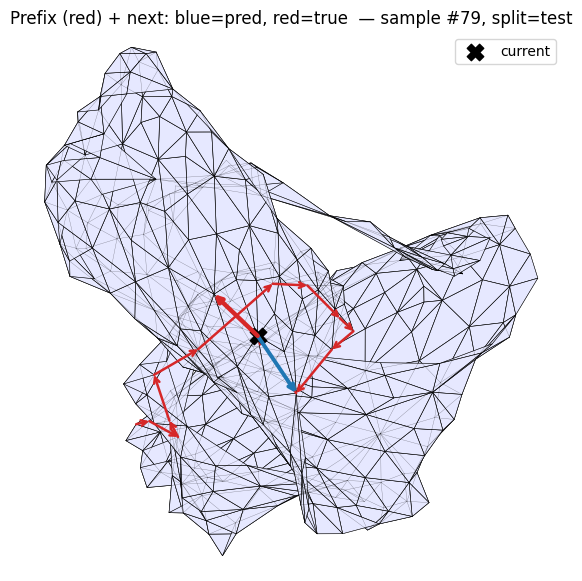

In [ ]:
test_metrics = evaluate("test")
print(f"Test — loss: {test_metrics['loss']:.4f}, "
      f"Top-1: {test_metrics['top1']:.3f}, Top-5: {test_metrics['top5']:.3f}")

def markov_from_train(last_nodes, target_nodes, train_idx, V):
    counts = np.ones((V, V), dtype=np.float64)  # Laplace smoothing
    for i in train_idx:
        v = int(last_nodes[i]); u = int(target_nodes[i])
        counts[v, u] += 1.0
    probs = counts / counts.sum(axis=1, keepdims=True)
    return probs

def eval_markov(probs, split_idx, N_idx_aligned):
    top1 = top5 = 0.0
    n = len(split_idx)
    for i in split_idx:
        v = int(last_nodes_np[i]); u_true = int(target_nodes_np[i])
        neighs = N_idx_aligned[v]
        valid = neighs[neighs != -1]
        if len(valid) == 0:
            n -= 1
            continue
        p = probs[v, valid]
        order = np.argsort(-p)  # descending
        pred1 = valid[order[:1]]
        pred5 = valid[order[:min(5, len(valid))]]
        top1 += float(u_true in pred1)
        top5 += float(u_true in pred5)
    return dict(top1=top1/max(1,n), top5=top5/max(1,n))

mk_probs = markov_from_train(last_nodes_np, target_nodes_np, train_idx, V)
mk_val = eval_markov(mk_probs, val_idx, N_idx_aligned)
mk_tst = eval_markov(mk_probs, test_idx, N_idx_aligned)
print(f"Markov — val Top-1: {mk_val['top1']:.3f}, Top-5: {mk_val['top5']:.3f} | "
      f"test Top-1: {mk_tst['top1']:.3f}, Top-5: {mk_tst['top5']:.3f}")

def _extract_positions(G):
    """Try to extract node 2D positions from graph attributes; fall back to spring layout."""
    pos = {}
    for n, d in G.nodes(data=True):
        if "pos" in d and d["pos"] is not None:
            pos[n] = d["pos"]
        elif "coords" in d:
            pos[n] = d["coords"]
        elif "coord" in d:
            pos[n] = d["coord"]
        elif "xy" in d:
            pos[n] = d["xy"]
        elif "x" in d and "y" in d:
            pos[n] = (d["x"], d["y"])
    if len(pos) != G.number_of_nodes():
        pos = nx.spring_layout(G, seed=CFG.seed, dim=2)
    P = np.zeros((G.number_of_nodes(), 2), dtype=np.float32)
    for n in range(G.number_of_nodes()):
        xy = pos[n]
        P[n,0] = float(xy[0]); P[n,1] = float(xy[1])
    return P

POS = _extract_positions(G_undir)  # [V,2]

from matplotlib.collections import PolyCollection

def triangles_from_B2(B1_np, B2_np):
    if B2_np is None:
        raise ValueError("B2.npy not found in dataset; cannot reconstruct faces.")
    V, E = B1_np.shape
    head_idx = np.argmax(B1_np > 0, axis=0)  # [E]
    tail_idx = np.argmax(B1_np < 0, axis=0)  # [E]
    tris = []
    seen = set()
    for t in range(B2_np.shape[1]):
        e_ids = np.where(np.abs(B2_np[:, t]) > 0)[0]
        if len(e_ids) != 3:
            # Non-triangular cell; skip
            continue
        nodes = set()
        for e in e_ids:
            nodes.add(int(head_idx[e]))
            nodes.add(int(tail_idx[e]))
        if len(nodes) != 3:
            # Degenerate; skip
            continue
        tri = tuple(sorted(nodes))
        if tri not in seen:
            seen.add(tri)
            tris.append(tri)
    return np.array(tris, dtype=int)

if DS["B2"] is None:
    print("Warning: B2 not available; cannot draw filled triangles. Falling back to wireframe.")
    TRIS = None
else:
    TRIS = triangles_from_B2(DS["B1"], DS["B2"])
    print(f"Recovered {len(TRIS)} triangles for filled-mesh rendering.")

def draw_filled_mesh(ax, POS, G, TRIS, face_color="#e9ecff", edge_color="black"):
    """
    Draw a light-filled triangular mesh like the screenshot.
    """
    if TRIS is not None and len(TRIS) > 0:
        verts = [POS[tri] for tri in TRIS]  # list of (3,2) arrays
        pc = PolyCollection(
            verts,
            facecolors=face_color,
            edgecolors=edge_color,
            linewidths=0.4,
            alpha=1.0
        )
        ax.add_collection(pc)
    else:
        # Wireframe fallback if no B2
        for (a, b) in G.edges():
            ax.plot([POS[a,0], POS[b,0]], [POS[a,1], POS[b,1]], linewidth=0.4, color=edge_color, alpha=0.8)

@torch.no_grad()
def _reconstruct_prefix_nodes(sample_i, head_idx_np=None, tail_idx_np=None):
    """
    Reconstruct the ordered prefix path (nodes) that ends at last_nodes[sample_i],
    using the directed flows in flows_in[sample_i].
    Assumes flows are -1/0/1 on edges; +1 means tail->head along B1 orientation.
    """
    f = flows_in_np[sample_i]              # [E]
    if head_idx_np is None or tail_idx_np is None:
        # fall back from torch tensors if needed
        head_idx_np = edges_i_t.cpu().numpy()
        tail_idx_np = edges_j_t.cpu().numpy()

    # Build directed incoming list from the flow
    incoming = {v: [] for v in range(V)}
    for e, fe in enumerate(f):
        if fe == 0:
            continue
        u = int(tail_idx_np[e]) if fe > 0 else int(head_idx_np[e])
        v = int(head_idx_np[e]) if fe > 0 else int(tail_idx_np[e])
        incoming[v].append(u)

    # Walk backward from last node until no predecessor
    v_last = int(last_nodes_np[sample_i])
    seq = [v_last]
    guard = 0
    while guard < (len(f) + 5):
        preds = incoming.get(seq[-1], [])
        if len(preds) == 0:
            break
        # should be unique for a path; take the only predecessor
        prev_v = preds[0]
        seq.append(prev_v)
        guard += 1
    seq.reverse()  # start -> ... -> last
    return seq  # list of node ids

def _arrow(ax, a, b, color, lw=2.0, z=6):
    ax.annotate(
        "", xy=(POS[b,0], POS[b,1]), xytext=(POS[a,0], POS[a,1]),
        arrowprops=dict(arrowstyle="->", lw=lw, color=color, shrinkA=0, shrinkB=0),
        zorder=z
    )

@torch.no_grad()
def visualize_prefix_and_next_mesh(split="test", sample_index=None, max_prev=None):
    """
    Filled-triangle mesh background.
    - Draw the **prefix path** up to the current node with RED arrows.
    - Draw the **predicted next** arrow in BLUE.
    - Draw the **true next** arrow in RED (thicker).
    Set max_prev (int) to truncate the number of previous steps for clarity.
    """
    split_ids = {"train": train_idx, "val": val_idx, "test": test_idx}[split]
    if len(split_ids) == 0:
        print(f"No samples in split '{split}'.");
        return

    # pick a sample
    if sample_index is None:
        i = int(np.random.default_rng(CFG.seed).choice(split_ids, size=1)[0])
    else:
        i = int(split_ids[sample_index % len(split_ids)])

    prefix_nodes = _reconstruct_prefix_nodes(i, head_idx, tail_idx)
    if max_prev is not None and len(prefix_nodes) > max_prev + 1:
        # keep the tail of the path (last `max_prev` hops)
        prefix_nodes = prefix_nodes[-(max_prev+1):]

    # features + logits for next step
    X0, last_nodes_b, _tgt_idx_b = batch_to_device(np.array([i]))
    neigh_logits = model.forward_neigh_logits(X0, last_nodes_b)  # [1, D]
    v = int(last_nodes_np[i])                                     # current (last) node
    u_true = int(target_nodes_np[i])                              # ground-truth next
    pred_slot = int(neigh_logits.argmax(dim=1).item())
    u_pred = int(N_idx_aligned[v, pred_slot])

    # ---- plot
    fig, ax = plt.subplots(figsize=(7,7))
    draw_filled_mesh(ax, POS, G_undir, TRIS, face_color="#e6e8ff", edge_color="black")

    # subtle wire overlay
    for (a, b) in G_undir.edges():
        ax.plot([POS[a,0], POS[b,0]], [POS[a,1], POS[b,1]], linewidth=0.25, color="black", alpha=0.45, zorder=1)

    # draw prefix path (ground-truth so far) in RED
    for a, b in zip(prefix_nodes[:-1], prefix_nodes[1:]):
        _arrow(ax, a, b, color="tab:red", lw=1.8, z=5)

    # current node
    ax.scatter(POS[v,0], POS[v,1], s=140, marker="X", color="black", zorder=7, label="current")

    # next-step: BLUE predicted, RED true (thicker)
    _arrow(ax, v, u_pred, color="tab:blue", lw=2.8, z=8)
    _arrow(ax, v, u_true, color="tab:red",  lw=3.2, z=9)

    # halo if correct
    if u_pred == u_true:
        ax.scatter(POS[u_true,0], POS[u_true,1], s=180, facecolors="none", edgecolors="tab:blue", linewidths=2, zorder=10)

    ax.set_title(f"Prefix (red) + next: blue=pred, red=true  — sample #{i}, split={split}")
    ax.axis("equal"); ax.axis("off"); ax.legend(loc="upper right")
    plt.show()

# Example (show last ~20 steps of the prefix for readability):
visualize_prefix_and_next_mesh(split="test", max_prev=20)


In [ ]:
class EdgeRestrictionMLP(nn.Module):
    def __init__(self, d: int, f_in: int, hidden: int = 64, scale: float = 0.1):
        super().__init__()
        #TODO: Implement the constructor 

    def forward(self, edge_attr: torch.Tensor):
        """
        edge_attr: [E, F]
        returns:
          Ri, Rj: [E, d, d]
        """
        #TODO: Implement the forward pass 

class LearnedSheafLayer(nn.Module):
    def __init__(self, d: int, f_edge: int, hidden: int = 64, dropout: float = 0.0, scale: float = 0.1):
        super().__init__()
        #TODO: Implement the constructor for Learned-Restriction SNNLayer

    def forward(self, x: torch.Tensor, edges_i: torch.Tensor, edges_j: torch.Tensor, edge_attr: torch.Tensor):
        """
        x:        [B, V, d]
        edges_i:  [E]
        edges_j:  [E]
        edge_attr:[E, F]
        """
        #TODO: Implement the forward pass for Learned-Restriction SNNLayer


class SheafSNN_Learned(nn.Module):
    def __init__(self, V: int, D: int, d_in: int = 2, d_hid: int = 64, L: int = 3, dropout: float = 0.0, scale: float = 0.1):
        super().__init__()
        #TODO: Implement the constructor. LearnedSheafLayer should be followed by LayerNorm

    def forward_node_logits(self, X0: torch.Tensor, edges_i: torch.Tensor, edges_j: torch.Tensor, edge_attr: torch.Tensor):
        #TODO: Implement the forward pass. LearnedSheafLayer should be followed by LayerNorm
        return logits

    def forward_neigh_logits(self, X0: torch.Tensor, last_nodes: torch.Tensor):
        node_logits = self.forward_node_logits(
            X0,
            edges_i_t.to(X0.device),
            edges_j_t.to(X0.device),
            edge_attr_t.to(X0.device)
        )
        neigh_logits, _ = gather_neighbor_logits(node_logits, last_nodes)
        return neigh_logits

model_learned = SheafSNN_Learned(
    V=V, D=D, d_in=2, d_hid=CFG.emb_dim, L=CFG.layers, dropout=CFG.dropout, scale=0.1
).to(device)

model_learned = train_model(model_learned, epochs=CFG.epochs, lr=CFG.lr, wd=CFG.weight_decay)

# Evaluate
val_learn = evaluate_model(model_learned, "val")
tst_learn = evaluate_model(model_learned, "test")
print(f"[Learned-Restrictions]  VAL  loss={val_learn['loss']:.4f}  top1={val_learn['top1']:.3f}  top5={val_learn['top5']:.3f}")
print(f"[Learned-Restrictions]  TEST loss={tst_learn['loss']:.4f}  top1={tst_learn['top1']:.3f}  top5={tst_learn['top5']:.3f}")


[LearnedR Ep 01] train_loss=1.6077 | val_loss=1.1049 val_top1=0.562 val_top5=1.000
[LearnedR Ep 02] train_loss=1.1448 | val_loss=0.9930 val_top1=0.613 val_top5=1.000
[LearnedR Ep 03] train_loss=1.0682 | val_loss=0.9220 val_top1=0.688 val_top5=1.000
[LearnedR Ep 04] train_loss=1.0050 | val_loss=0.9103 val_top1=0.700 val_top5=1.000
[LearnedR Ep 05] train_loss=0.9509 | val_loss=0.8883 val_top1=0.637 val_top5=1.000
[LearnedR Ep 06] train_loss=0.9046 | val_loss=0.8944 val_top1=0.662 val_top5=1.000
[LearnedR Ep 07] train_loss=0.8609 | val_loss=0.8622 val_top1=0.700 val_top5=1.000
[LearnedR Ep 08] train_loss=0.8165 | val_loss=0.8171 val_top1=0.750 val_top5=1.000
[LearnedR Ep 09] train_loss=0.7732 | val_loss=0.8443 val_top1=0.688 val_top5=1.000
[LearnedR Ep 10] train_loss=0.7343 | val_loss=0.8294 val_top1=0.725 val_top5=1.000
[LearnedR Ep 11] train_loss=0.7043 | val_loss=0.8330 val_top1=0.675 val_top5=1.000
[LearnedR Ep 12] train_loss=0.6836 | val_loss=0.8310 val_top1=0.713 val_top5=1.000
[Lea

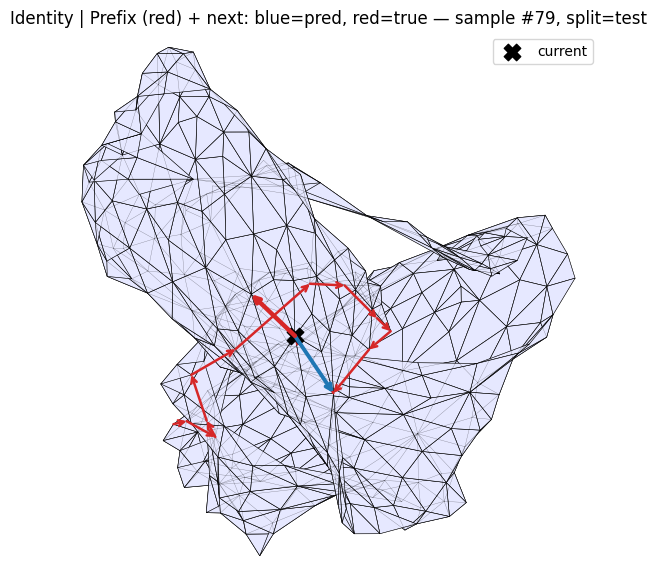

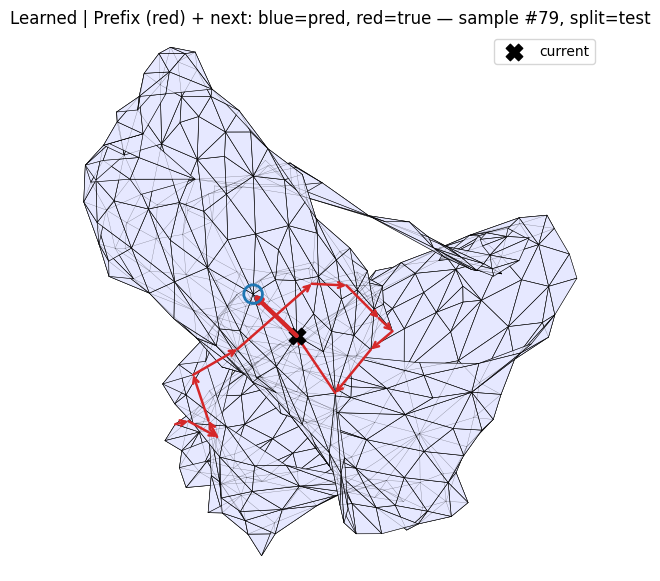

In [ ]:

@torch.no_grad()
def visualize_prefix_and_next_mesh_with(model_to_use, split="test", sample_index=None, max_prev=20, title_prefix=None):
    split_ids = {"train": train_idx, "val": val_idx, "test": test_idx}[split]
    if len(split_ids) == 0:
        print(f"No samples in split '{split}'.");
        return

    if sample_index is None:
        i = int(np.random.default_rng(CFG.seed).choice(split_ids, size=1)[0])
    else:
        i = int(split_ids[sample_index % len(split_ids)])

    # reconstruct prefix path nodes from flows
    prefix_nodes = _reconstruct_prefix_nodes(i, head_idx, tail_idx)
    if max_prev is not None and len(prefix_nodes) > max_prev + 1:
        prefix_nodes = prefix_nodes[-(max_prev+1):]

    # logits for next step
    X0, last_nodes_b, _tgt_idx_b = batch_to_device(np.array([i]))
    neigh_logits = model_to_use.forward_neigh_logits(X0, last_nodes_b)  # [1, D]
    v = int(last_nodes_np[i])                                           # current (last) node
    u_true = int(target_nodes_np[i])                                    # ground-truth next
    pred_slot = int(neigh_logits.argmax(dim=1).item())
    u_pred = int(N_idx_aligned[v, pred_slot])

    fig, ax = plt.subplots(figsize=(7,7))
    draw_filled_mesh(ax, POS, G_undir, TRIS, face_color="#e6e8ff", edge_color="black")
    for (a, b) in G_undir.edges():
        ax.plot([POS[a,0], POS[b,0]], [POS[a,1], POS[b,1]], linewidth=0.25, color="black", alpha=0.45, zorder=1)

    def _arrow(ax, a, b, color, lw=2.0, z=6):
        ax.annotate("", xy=(POS[b,0], POS[b,1]), xytext=(POS[a,0], POS[a,1]),
                    arrowprops=dict(arrowstyle="->", lw=lw, color=color, shrinkA=0, shrinkB=0), zorder=z)

    for a, b in zip(prefix_nodes[:-1], prefix_nodes[1:]):
        _arrow(ax, a, b, color="tab:red", lw=1.8, z=5)

    ax.scatter(POS[v,0], POS[v,1], s=140, marker="X", color="black", zorder=7, label="current")

    _arrow(ax, v, u_pred, color="tab:blue", lw=2.8, z=8)
    _arrow(ax, v, u_true, color="tab:red",  lw=3.2, z=9)
    if u_pred == u_true:
        ax.scatter(POS[u_true,0], POS[u_true,1], s=180, facecolors="none", edgecolors="tab:blue", linewidths=2, zorder=10)

    title = f"Prefix (red) + next: blue=pred, red=true — sample #{i}, split={split}"
    if title_prefix: title = f"{title_prefix} | " + title
    ax.set_title(title)
    ax.axis("equal"); ax.axis("off"); ax.legend(loc="upper right")
    plt.show()


visualize_prefix_and_next_mesh_with(model, split="test", max_prev=20, title_prefix="Identity")

if 'model_learned' in globals():
    visualize_prefix_and_next_mesh_with(model_learned, split="test", max_prev=20, title_prefix="Learned")
